# EDA de QuickDraw

Cargamos los datos preparados, revisamos sus dimensiones y mostramos conteos, intensidades y ejemplos. El ETL selecciona hasta 5,000 imágenes por clase y revisa la muestra antes de dividirla. La normalización se hace dentro de la CNN.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from etl import cargar_datos
from quickdraw_config import CLASES_ES

datos = cargar_datos()
x_train, y_train = datos['x_train'], datos['y_train']
x_val, y_val = datos['x_val'], datos['y_val']
x_test, y_test = datos['x_test'], datos['y_test']


## 1. Dimensiones y limpieza

Cada imagen tiene 28 filas, 28 columnas y un canal de gris. Los conteos de limpieza corresponden solo a la muestra seleccionada, no a todos los archivos de Google.

In [2]:
print('Entrenamiento:', x_train.shape, y_train.shape)
print('Validación:', x_val.shape, y_val.shape)
print('Prueba:', x_test.shape, y_test.shape)
print('Tipo de imagen:', x_train.dtype)
print('Imágenes seleccionadas inicialmente:', int(datos['seleccionadas']))
vacias, repetidas, contradictorias = datos['limpieza']
print('Vacías:', vacias)
print('Apariciones repetidas:', repetidas)
print('Patrones con etiquetas distintas:', contradictorias)
print('Imágenes finales por clase:', int(datos['por_clase']))


Entrenamiento: (35000, 28, 28, 1) (35000,)
Validación: (7500, 28, 28, 1) (7500,)
Prueba: (7500, 28, 28, 1) (7500,)
Tipo de imagen: uint8
Imágenes seleccionadas inicialmente: 50000
Vacías: 0
Apariciones repetidas: 0
Patrones con etiquetas distintas: 0
Imágenes finales por clase: 5000


## 2. Cantidades por categoría

Cada clase tiene el mismo número de imágenes. Entrenamiento usa el 70 %, validación el 15 % y prueba el resto.

Clase             Train      Val     Test
gato               3500      750      750
pez                3500      750      750
bicicleta          3500      750      750
avión              3500      750      750
casa               3500      750      750
árbol              3500      750      750
reloj              3500      750      750
paraguas           3500      750      750
helado             3500      750      750
estrella           3500      750      750


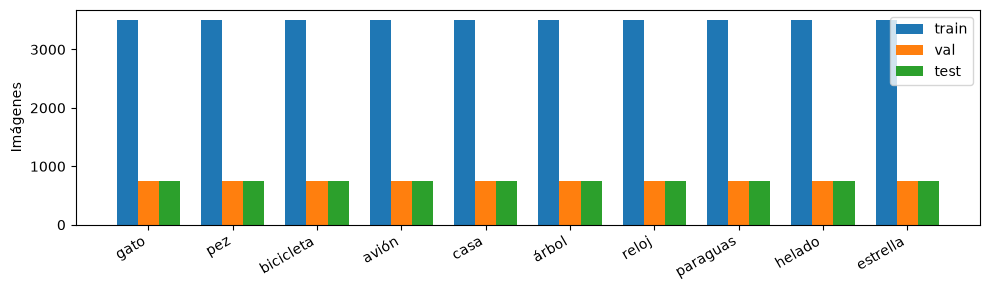

In [3]:
partes = {'train': y_train, 'val': y_val, 'test': y_test}
conteos = {nombre: np.bincount(y, minlength=10) for nombre, y in partes.items()}
print(f"{'Clase':<14} {'Train':>8} {'Val':>8} {'Test':>8}")
for i, clase in enumerate(CLASES_ES):
    print(f"{clase:<14} {conteos['train'][i]:>8} {conteos['val'][i]:>8} {conteos['test'][i]:>8}")
fig, ax = plt.subplots(figsize=(10, 3))
posiciones = np.arange(10)
for j, nombre in enumerate(partes):
    ax.bar(posiciones + (j - 1) * .25, conteos[nombre], width=.25, label=nombre)
ax.set_xticks(posiciones, CLASES_ES, rotation=30, ha='right')
ax.set_ylabel('Imágenes')
ax.legend()
plt.tight_layout()
plt.show()


## 3. Intensidades de entrenamiento

0 corresponde a negro y 255 a blanco. Para explorar los píxeles y los ejemplos usamos únicamente entrenamiento; validación y prueba se reservan para evaluar los modelos.

Rango: 0 a 255
Media de intensidad: 42.302800364431484
Fracción de píxeles distintos de cero: 0.2808548469387755


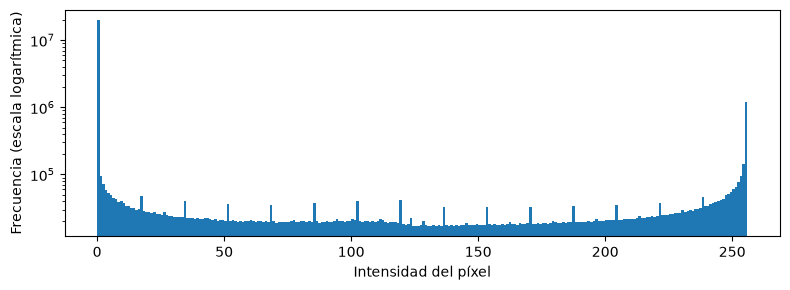

In [4]:
print('Rango:', x_train.min(), 'a', x_train.max())
print('Media de intensidad:', x_train.mean())
print('Fracción de píxeles distintos de cero:', np.count_nonzero(x_train) / x_train.size)
plt.figure(figsize=(8, 3))
plt.hist(x_train.ravel(), bins=256, range=(0, 256), log=True)
plt.xlabel('Intensidad del píxel')
plt.ylabel('Frecuencia (escala logarítmica)')
plt.tight_layout()
plt.show()


## 4. Ejemplos de dibujos

Mostramos dos imágenes de entrenamiento por clase. La semilla fija permite repetir la misma selección visual.

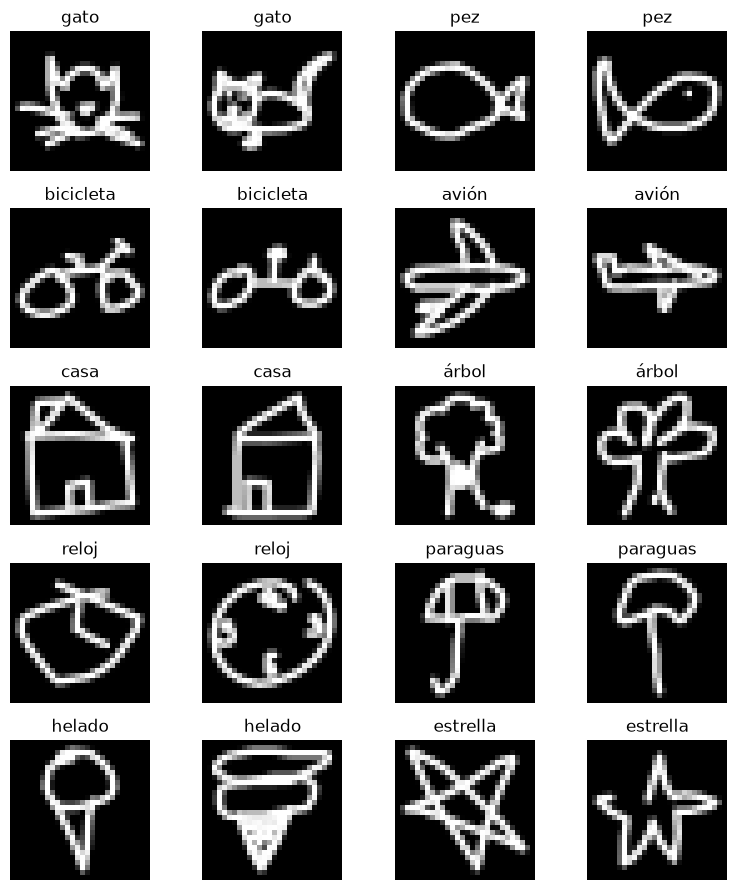

In [5]:
rng = np.random.default_rng(42)
fig, ejes = plt.subplots(5, 4, figsize=(8, 9))
for clase, nombre in enumerate(CLASES_ES):
    indices = np.flatnonzero(y_train == clase)
    elegidos = rng.choice(indices, size=2, replace=False)
    for columna, indice in enumerate(elegidos):
        ax = ejes[clase // 2, (clase % 2) * 2 + columna]
        ax.imshow(x_train[indice, ..., 0], cmap='gray', vmin=0, vmax=255)
        ax.set_title(nombre)
        ax.axis('off')
plt.tight_layout()
plt.show()
